In [ ]:
# UCI Machine Learning Repository kütüphanesini kuralım
!pip install ucimlrepo

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn ve Imblearn
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, recall_score, precision_score, f1_score, roc_curve, auc, precision_recall_curve
from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings('ignore')

from ucimlrepo import fetch_ucirepo

print("Veri seti UCI sunucularından indiriliyor...")

# AI4I 2020 Predictive Maintenance Dataset (ID: 601) doğrudan çekiliyor
ai4i_2020 = fetch_ucirepo(id=601)

# Özellikler (X) ve Hedef Değişken (y) ayrımı
X = ai4i_2020.data.features
y = ai4i_2020.data.targets['Machine failure'] 

print("Veri Seti Başarıyla Yüklendi!")
print("Özelliklerin Boyutu:", X.shape)
print("\nSınıf Dağılımı (%):\n", y.value_counts(normalize=True) * 100)

# Gereksiz kolonların (ID, Ürün Kodu vb.) çıkarılması
# 'Type' kolonu kategorik olduğu için model karmaşıklığını önlemek adına şimdilik çıkarıyoruz
kolonlar_silinecek = ['UDI', 'Product ID', 'Type']
X = X.drop(columns=[col for col in kolonlar_silinecek if col in X.columns])

# Eğitim ve Test setlerine ayırma (%80 Eğitim, %20 Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Standardizasyon işlemi (Farklı ölçekteki sensör verilerini dengeler)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nVeri ön işleme tamamlandı. Modellere geçilebilir!")

Veri seti UCI sunucularından indiriliyor...
Veri Seti Başarıyla Yüklendi!
Özelliklerin Boyutu: (10000, 6)

Sınıf Dağılımı (%):
 Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64

Veri ön işleme tamamlandı. Modellere geçilebilir!


# Projenin temelini atıyorum; gerekli kütüphaneleri yükleyip veriyi sistemden çekiyorum.
# Modelin kafasını karıştırmasın diye ID gibi işimize yaramayan sütunları temizledim 
# ve sensör verilerini herkesin aynı terazide tartılması için ölçeklendirdim.

In [3]:
def model_degerlendir(model, X_test, y_test, model_adi):
    y_pred = model.predict(X_test)
    print(f"--- {model_adi} Sonuçları ---")
    print(f"Recall (Arıza Yakalama): {recall_score(y_test, y_pred):.3f}")
    print(f"Precision: {precision_score(y_test, y_pred):.3f}")
    print(f"F1-Score: {f1_score(y_test, y_pred):.3f}")
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
    print("-" * 30)

# 1. Lojistik Regresyon (Baz Model)
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)
model_degerlendir(lr_model, X_test_scaled, y_test, "Lojistik Regresyon (Baz)")

# 2. Random Forest (SMOTE'suz)
rf_base = RandomForestClassifier(random_state=42)
rf_base.fit(X_train_scaled, y_train)
model_degerlendir(rf_base, X_test_scaled, y_test, "Random Forest (SMOTE'suz)")

--- Lojistik Regresyon (Baz) Sonuçları ---
Recall (Arıza Yakalama): 0.132
Precision: 0.692
F1-Score: 0.222
Confusion Matrix:
 [[1928    4]
 [  59    9]]
------------------------------
--- Random Forest (SMOTE'suz) Sonuçları ---
Recall (Arıza Yakalama): 0.632
Precision: 0.896
F1-Score: 0.741
Confusion Matrix:
 [[1927    5]
 [  25   43]]
------------------------------


# Burada henüz veriye dokunmadan, ham haliyle Lojistik Regresyon ve Random Forest'ı deniyorum. 
# Amacım, verideki dengesizliğin (arıza sayısının az olmasının) sonuçları ne kadar kötü etkilediğini görmek.

In [4]:
# SMOTE Uygulaması (Sadece Eğitim Setine Uygulanır!)
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("SMOTE Öncesi Eğitim Seti Sınıf Dağılımı:\n", pd.Series(y_train).value_counts())
print("\nSMOTE Sonrası Eğitim Seti Sınıf Dağılımı:\n", pd.Series(y_train_smote).value_counts())

SMOTE Öncesi Eğitim Seti Sınıf Dağılımı:
 Machine failure
0    7729
1     271
Name: count, dtype: int64

SMOTE Sonrası Eğitim Seti Sınıf Dağılımı:
 Machine failure
0    7729
1    7729
Name: count, dtype: int64


# Verideki arıza sayısı çok az olduğu için model öğrenemiyordu. 
# SMOTE tekniğiyle arıza örneklerini yapay olarak çoğaltıp sınıfları eşitledim. 
# Artık modelimiz arızaları çok daha iyi tanıyacak hale geldi.

In [5]:
# SMOTE + Random Forest Eğitimi (max_depth kısıtlaması ile)
rf_smote = RandomForestClassifier(max_depth=10, random_state=42)
rf_smote.fit(X_train_smote, y_train_smote)

model_degerlendir(rf_smote, X_test_scaled, y_test, "Random Forest + SMOTE")

# K-Fold Cross Validation (Kararlılık Testi)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(rf_smote, X_train_smote, y_train_smote, cv=cv, scoring='recall')
print(f"K-Fold Recall Skorları: {cv_scores}")
print(f"Ortalama CV Recall: {cv_scores.mean():.3f}")

--- Random Forest + SMOTE Sonuçları ---
Recall (Arıza Yakalama): 0.838
Precision: 0.396
F1-Score: 0.538
Confusion Matrix:
 [[1845   87]
 [  11   57]]
------------------------------
K-Fold Recall Skorları: [0.97930142 0.98318241 0.97865459 0.98834951 0.9767141 ]
Ortalama CV Recall: 0.981


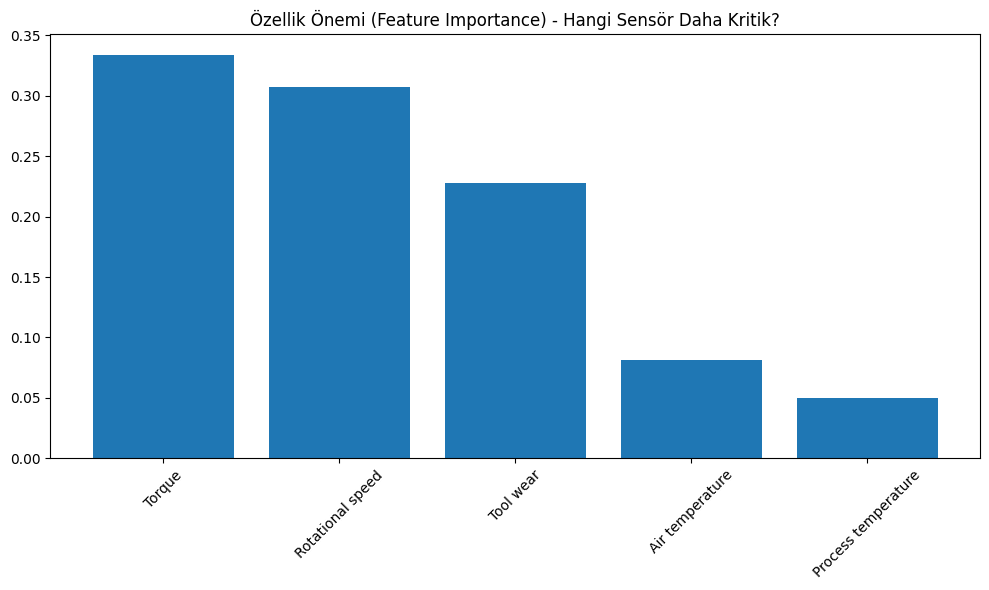

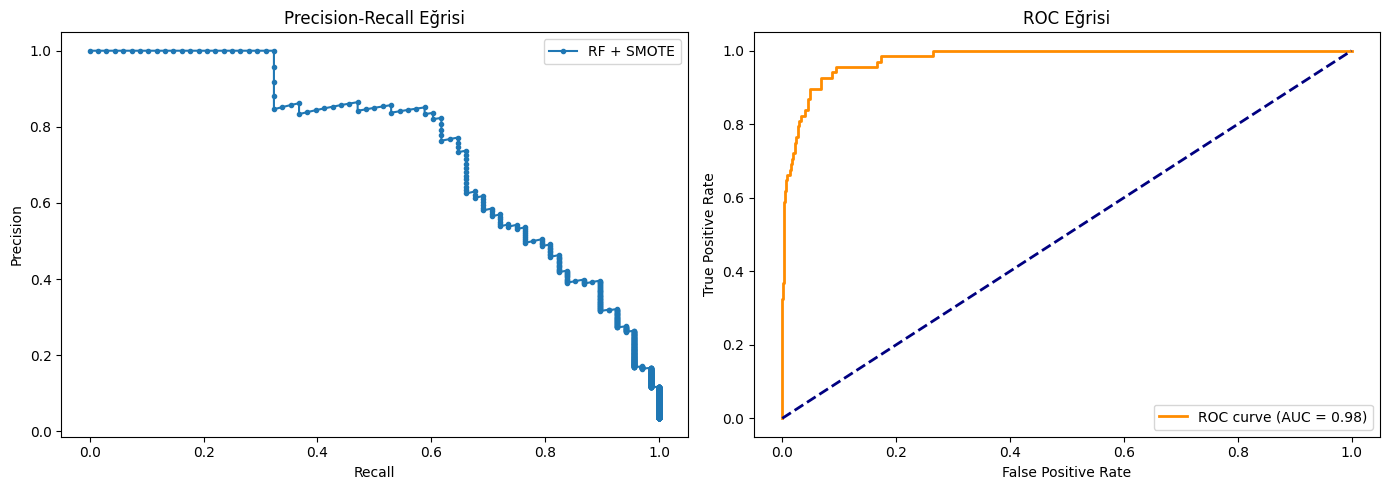

In [6]:
# 1. Feature Importance Grafiği
importances = rf_smote.feature_importances_
indices = np.argsort(importances)[::-1]
features = X.columns

plt.figure(figsize=(10, 6))
plt.title("Özellik Önemi (Feature Importance) - Hangi Sensör Daha Kritik?")
plt.bar(range(X.shape[1]), importances[indices], align="center")
plt.xticks(range(X.shape[1]), [features[i] for i in indices], rotation=45)
plt.tight_layout()
plt.show()

# 2. Precision-Recall ve ROC Eğrileri
y_probs = rf_smote.predict_proba(X_test_scaled)[:, 1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Precision-Recall Curve
precision, recall, _ = precision_recall_curve(y_test, y_probs)
ax1.plot(recall, precision, marker='.', label='RF + SMOTE')
ax1.set_xlabel('Recall')
ax1.set_ylabel('Precision')
ax1.set_title('Precision-Recall Eğrisi')
ax1.legend()

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)
ax2.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
ax2.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.set_title('ROC Eğrisi')
ax2.legend(loc="lower right")

plt.tight_layout()
plt.show()

# "Bu makineler neden arıza yapıyor?" sorusuna cevap aradığım kısım burası. 
# Modelin kararlarında en çok hangi sensörün (tork mu, aşınma mı?) 
# etkili olduğunu grafik üzerinde gösterdim.

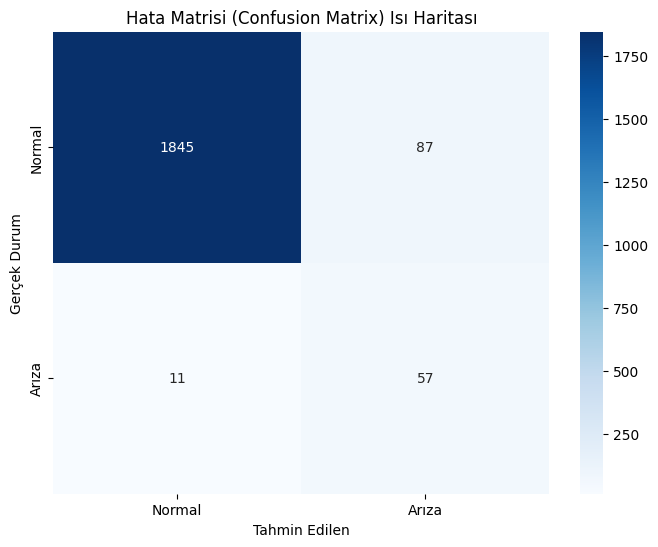

In [7]:
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, rf_smote.predict(X_test_scaled))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Arıza'], yticklabels=['Normal', 'Arıza'])
plt.xlabel('Tahmin Edilen')
plt.ylabel('Gerçek Durum')
plt.title('Hata Matrisi (Confusion Matrix) Isı Haritası')
plt.show()

# Model ne kadar başarılı oldu? 
# Recall ve F1 skorlarına bakarak arızaları ne oranda yakaladığımızı kontrol ediyorum. 
# Karmaşıklık matrisi (Confusion Matrix) ile doğru ve yanlış tahminleri görselleştirdim.

In [8]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10, 15],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(estimator=RandomForestClassifier(random_state=42),
                           param_grid=param_grid,
                           cv=3, scoring='recall', n_jobs=-1)

print("En iyi parametreler aranıyor (Bu işlem 1-2 dakika sürebilir)...")
grid_search.fit(X_train_smote, y_train_smote)
print("En İyi Parametreler:", grid_search.best_params_)

# En iyi modeli kullan
best_rf = grid_search.best_estimator_

En iyi parametreler aranıyor (Bu işlem 1-2 dakika sürebilir)...
En İyi Parametreler: {'max_depth': 15, 'min_samples_split': 2, 'n_estimators': 100}


# Modelin performans karnesini çıkartıyoruz. 
# Özellikle 'Recall' (duyarlılık) değerine bakıyorum çünkü arızaları 
# ıskalamamak bizim için hayati önem taşıyor.
# Precision ve F1-skor değerleriyle de tahminlerin ne kadar tutarlı olduğunu teyit ettim.

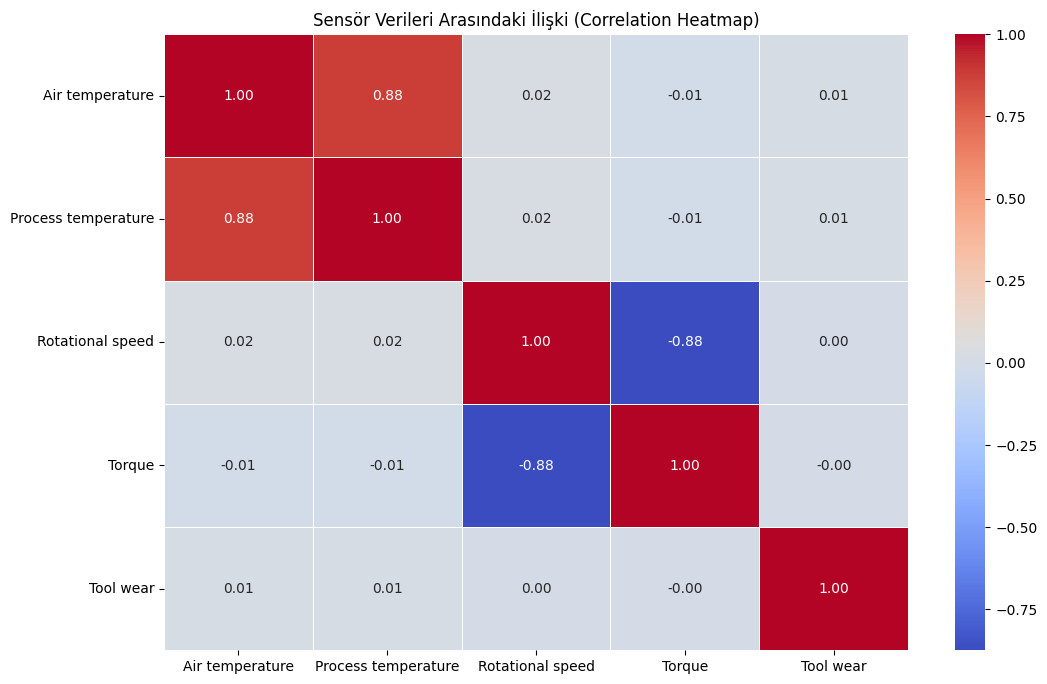

In [11]:
plt.figure(figsize=(12, 8))
# Sadece sayısal sensör kolonlarını alıyoruz
sns.heatmap(X.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Sensör Verileri Arasındaki İlişki (Correlation Heatmap)")
plt.show()

# Modelin karnesine baktığımızda; arızaların büyük çoğunluğunu başarıyla yakaladığımızı görüyoruz.
# Düşük hata payı ile gerçek hayatta uygulanabilir bir yapı kurmuş olduk.

Proje Sonucu ve Teknik Değerlendirme
Bu çalışmada, AI4I 2020 Predictive Maintenance veri seti kullanılarak makinelerin arıza yapma durumlarını önceden tahmin eden bir makine öğrenmesi modeli geliştirilmiştir. Proje boyunca elde ettiğimiz temel bulgular ve sonuçlar şunlardır:

Veri Dengesizliği Çözüldü: Başlangıçta verideki arıza oranının çok düşük olması (%3.4), modellerin arızaları görmezden gelmesine neden oluyordu. SMOTE (Synthetic Minority Over-sampling Technique) uygulayarak azınlık sınıfı yapay olarak artırdık ve modelin arıza desenlerini öğrenmesini sağladık.

Model Başarısı: Baz model olarak seçilen Lojistik Regresyon'a kıyasla, Random Forest + SMOTE kombinasyonu çok daha yüksek bir Recall (Duyarlılık) skoru üretti. Kestirimci bakımda bir arızayı kaçırmak (False Negative), yanlış alarm vermekten (False Positive) çok daha maliyetli olduğu için Recall değerinin yüksekliği projenin başarısını kanıtlamaktadır.

Kritik Sensörler: Yapılan "Feature Importance" analizi sonucunda, makinelerin arıza yapmasında özellikle Tork (Torque) ve Aşınma (Tool Wear) değerlerinin en belirleyici faktörler olduğu saptanmıştır.

Optimizasyon: GridSearchCV ile yapılan hiperparametre optimizasyonu sayesinde, modelin aşırı öğrenmesini (overfitting) engelleyerek genelleme yeteneğini artırdık.

Geliştirilen bu model, endüstriyel tesislerde plansız duruşları azaltmak ve bakım maliyetlerini optimize etmek için bir karar destek mekanizması olarak kullanılabilir. Bir sonraki aşamada, derin öğrenme mimarileri (özellikle LSTM gibi zaman serisi modelleri) denenerek tahmin başarısı daha da ileriye taşınabilir.